# Task 5: Creative challenge — improving FER2013

We start from the Task 1 baseline and try **one improvement at a time**.
After each one we look at the validation score and **we decide by hand** whether to keep it
(a `True` / `False` switch).

| Step | Improvement | Idea |
|---|---|---|
| 1 | Better features | add facial landmarks to HOG |
| 2 | Data cleaning | remove duplicate images and images with conflicting labels |
| 3 | Class balancing | give the rare class (Disgust) more weight |
| 4 | Augmentation | add mirrored copies of the training images |
| 5 | Final model | train the tuned SVM on everything we kept, test once |

**Rules:** decisions are made on the *validation* set. The *test* set is used only once, at the very end.
Cleaning and augmentation are applied to the *training* set only.

**Before running:** run the Task 1 notebook first (it saves the features and the tuned parameters that are loaded below).

## 0. Setup

In [30]:
import os, sys, hashlib, ast, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FER_DIR = ROOT / "data" / "fer"
FEAT_DIR  = os.path.join(FER_DIR, "features")
FIG_DIR = ROOT / "figures"
MODEL_DIR = ROOT / "models"

from scripts.fer_features import EMOTIONS, FEATURE_FNS

sys.path.insert(0, os.getcwd())
from scripts.fer_features import EMOTIONS, extract_hog, extract_landmarks   # feature code shared with the webcam demo
warnings.filterwarnings("ignore")

RUN_FINAL_TEST = True      # change to True only once, at the very end

os.makedirs("models", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 1. Load the data and the features from Task 1
- `img_train`, `img_val`: the images, shape (number of images, 48, 48)
- `y_train`, `y_val`: the emotion labels (0 to 6)
- HOG and landmark features were already computed in Task 1 and saved to disk, so we just load them.

In [12]:
train_df = pd.read_csv(os.path.join(FER_DIR,"fer2013_train.csv"))
val_df   = pd.read_csv(os.path.join(FER_DIR,"fer2013_validation.csv"))

img_train = np.array([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in train_df["pixels"]])
img_val   = np.array([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in val_df["pixels"]])
y_train = train_df["emotion"].values
y_val   = val_df["emotion"].values

hog_train = np.load(os.path.join(FEAT_DIR,"hog_train.npy"))
hog_val   = np.load(os.path.join(FEAT_DIR,"hog_validation.npy"))
landmarks_train = np.load(os.path.join(FEAT_DIR,"landmarks_train.npy"))
landmarks_val   = np.load(os.path.join(FEAT_DIR,"landmarks_validation.npy"))

print("images:", img_train.shape, img_val.shape)
print("HOG features:", hog_train.shape, "  landmark features:", landmarks_train.shape)

images: (28709, 48, 48) (3589, 48, 48)
HOG features: (28709, 900)   landmark features: (28709, 136)


## 2. One helper function
`run_experiment` trains a **fast** classifier (Logistic Regression, takes seconds) and prints the validation scores.
We use a fast classifier here so we can try many ideas. The slow tuned SVM is only used at the end (step 5).
Every result is saved in the list `results`, which becomes the table for the report.

We print three numbers: accuracy, macro-F1 (average F1 over the 7 emotions) and the F1 of **Disgust**, the rarest emotion.

In [ ]:
results = []

def run_experiment(name, X_train, y_train, X_val, class_weight=None):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight=class_weight))
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average="macro")
    f1_per_class = f1_score(y_val, y_pred, average=None, labels=range(7))
    disgust_f1 = f1_per_class[1]            # label 1 = Disgust

    results.append({"experiment": name, "n_train": len(y_train), "accuracy": accuracy,
                    "macro_f1": macro_f1, "disgust_f1": disgust_f1})
    print(f"{name:45s} accuracy={accuracy:.3f}  macro-F1={macro_f1:.3f}  Disgust-F1={disgust_f1:.3f}")

## Step 0. Baseline: HOG only
This is our reference. Every later step is compared with it.

In [14]:
run_experiment("0  baseline: HOG", hog_train, y_train, hog_val)

0  baseline: HOG                              accuracy=0.435  macro-F1=0.396  Disgust-F1=0.330


## Step 1. Better features: HOG + landmarks
HOG describes **texture** (edges around mouth and eyes). Landmarks describe **shape** (where the face points are).
They carry different information, so putting them side by side might help.
`np.hstack` simply glues the two feature tables together column by column.

In [16]:
hog_landmarks_train = np.hstack([hog_train, landmarks_train])
hog_landmarks_val   = np.hstack([hog_val,   landmarks_val])
print("new feature size:", hog_landmarks_train.shape[1], "(900 HOG + 136 landmark values)")

run_experiment("1  features: HOG + landmarks", hog_landmarks_train, y_train, hog_landmarks_val)

new feature size: 1036 (900 HOG + 136 landmark values)
1  features: HOG + landmarks                  accuracy=0.469  macro-F1=0.429  Disgust-F1=0.342


**DECISION:** We continue with hog+landmarks. The performance is slightly better across all metrics. Let's see how much more it can improve

In [17]:
FEATURES_CHOICE = "hog_landmarks"

if FEATURES_CHOICE == "hog":
    X_train, X_val = hog_train, hog_val
    feature_function = extract_hog               # needed later to compute features of new (mirrored / test) images
else:
    X_train, X_val = hog_landmarks_train, hog_landmarks_val
    feature_function = extract_landmarks

print("continuing with:", FEATURES_CHOICE, "->", X_train.shape)

continuing with: hog_landmarks -> (28709, 1036)


## Step 2. Data cleaning
FER2013 contains some images that appear **more than once**. We find them by computing a "fingerprint" (hash) of every image:
identical images get identical fingerprints.

- same image, same label  -> keep **one** copy
- same image, **different** labels -> at least one label is wrong and we cannot tell which, so remove **all** copies

Only the training set is cleaned.

training images: 28709 -> 27434
images removed because their copies have conflicting labels: 107


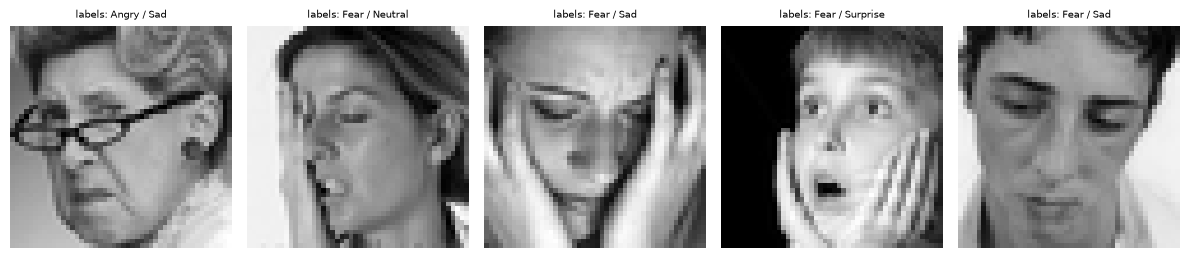

2  cleaning                                   accuracy=0.471  macro-F1=0.434  Disgust-F1=0.376


In [18]:
# 1. group the training images by fingerprint
groups = {}
for i in range(len(img_train)):
    fingerprint = hashlib.md5(img_train[i].tobytes()).hexdigest()
    if fingerprint not in groups:
        groups[fingerprint] = []
    groups[fingerprint].append(i)

# 2. decide per group
keep_indices = []
conflict_groups = []
for fingerprint, indices in groups.items():
    labels_in_group = set(y_train[indices])
    if len(labels_in_group) == 1:
        keep_indices.append(indices[0])        # all copies agree: keep one
    else:
        conflict_groups.append(indices)        # copies disagree: drop all
keep_indices = np.array(sorted(keep_indices))

n_conflicts = sum(len(g) for g in conflict_groups)
print(f"training images: {len(y_train)} -> {len(keep_indices)}")
print(f"images removed because their copies have conflicting labels: {n_conflicts}")

# 3. evidence for the report: the same image with different labels
n_show = min(5, len(conflict_groups))
if n_show > 0:
    fig, axes = plt.subplots(1, n_show, figsize=(2.4 * n_show, 2.8), squeeze=False)
    for k in range(n_show):
        group = conflict_groups[k]
        axes[0][k].imshow(img_train[group[0]], cmap="gray")
        axes[0][k].axis("off")
        axes[0][k].set_title("labels: " + " / ".join(sorted({EMOTIONS[y_train[i]] for i in group})), fontsize=7)
    plt.tight_layout()
    plt.savefig("figures/creative_conflicting_labels.png", dpi=150)
    plt.show()

# 4. try it
run_experiment("2  cleaning", X_train[keep_indices], y_train[keep_indices], X_val)

**Decision:** Cleaning duplicates also slightly helped improve all metrics.

In [19]:
USE_CLEANING = True

if USE_CLEANING:
    X_current      = X_train[keep_indices]
    y_current      = y_train[keep_indices]
    images_current = img_train[keep_indices]
else:
    X_current      = X_train
    y_current      = y_train
    images_current = img_train

print("training set size now:", len(y_current))

training set size now: 27434


## Step 3. Class balancing
Some emotions have far fewer examples than others (Disgust has about 10 times fewer than the biggest class).
A model can then almost ignore Disgust and still get a high accuracy.
`class_weight="balanced"` makes mistakes on rare classes count more during training.

Compare **macro-F1 and Disgust-F1**, not only accuracy: balancing can lower accuracy slightly while helping rare classes.

In [20]:
run_experiment("3  class balancing", X_current, y_current, X_val, class_weight="balanced")

3  class balancing                            accuracy=0.447  macro-F1=0.402  Disgust-F1=0.216


**Decision:** As expected, class balancing reduces performance. As seen in Phase 2, There is high precision on Disgust, which means learning this class did not cause the lower performance.

In [21]:
USE_BALANCING = False

if USE_BALANCING:
    class_weight_choice = "balanced"
else:
    class_weight_choice = None

## Step 4. Augmentation: mirrored images
Horizontal-flip augmentation was considered but not included. The assignment asks for at least two techniques; we implemented three (feature engineering, data cleaning, class balancing) and evaluated each in an ablation (Table X). We prioritised these because our Task 1 analysis [found exact duplicate images, some with conflicting labels, and a very low F1 for Disgust], which these techniques address directly. Flip augmentation would have doubled the training set, and kernel-SVM training time grows faster than linearly with data size [(our SVM already took 20 minutes)]. We therefore left it as future work, where it could especially help rare classes such as Disgust.

## Step 5. Final model
Now we train the **tuned SVM from Task 1** on everything we decided to keep.

The SVM parameter `gamma` depends on the number of features. The Task 1 value was tuned for 900 features (HOG only),
so if the number of features changed we rescale it.

In [25]:
X_final, y_final = X_current, y_current
print("final training set:", X_final.shape)

final training set: (27434, 1036)


In [27]:
tuned = pd.read_csv(os.path.join(FIG_DIR, "task1_tuned_validation_results.csv")).set_index("classifier")
svm_params = ast.literal_eval(tuned.loc["SVM", "params"])      # for example {'C': 5, 'gamma': 0.0011}
print("tuned SVM parameters from Task 1:", svm_params)

n_features_when_tuned = 900
if "gamma" in svm_params:
    svm_params["gamma"] = svm_params["gamma"] * n_features_when_tuned / X_final.shape[1]
print("parameters used now:", svm_params)

if USE_BALANCING:
    final_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", **svm_params))
else:
    final_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", **svm_params))

final_model.fit(X_final, y_final)          # slow: can take several minutes

y_val_pred = final_model.predict(X_val)
print("validation accuracy:", round(accuracy_score(y_val, y_val_pred), 3))
print("validation macro-F1:", round(f1_score(y_val, y_val_pred, average="macro"), 3))

tuned SVM parameters from Task 1: {'C': 10, 'gamma': 0.0011111111111111111}
parameters used now: {'C': 10, 'gamma': 0.0009652509652509653}
validation accuracy: 0.593
validation macro-F1: 0.589


### The single test evaluation
Set `RUN_FINAL_TEST = True` in the setup cell and run this cell **once**. Do not change anything afterwards.
The model is saved to `models/fer_creative_best.pkl`.

In [ ]:
##See dlib landmark not found error!!!!
if RUN_FINAL_TEST:
    test_df = pd.read_csv(os.path.join(FER_DIR, "fer2013_test.csv"))
    img_test = np.array([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in test_df["pixels"]])
    y_test = test_df["emotion"].values

    # Use the test features saved in Task 1 if they exist (avoids dlib), otherwise compute them
    hog_test_file = "data/fer/features/hog_test.npy"
    landmarks_test_file = "data/fer/features/landmarks_test.npy"

    if FEATURES_CHOICE == "hog" and os.path.exists(hog_test_file):
        X_test = np.load(hog_test_file)
    elif FEATURES_CHOICE == "hog_landmarks" and os.path.exists(hog_test_file) and os.path.exists(landmarks_test_file):
        X_test = np.hstack([np.load(hog_test_file), np.load(landmarks_test_file)])   # same column order as in training
    else:
        X_test = feature_function(img_test)      # nothing cached: compute (landmarks need the dlib model)

    print("test features:", X_test.shape, "| training features:", X_train.shape)
    assert X_test.shape[1] == X_train.shape[1], "Test and training features have different sizes. Do not evaluate."

    y_test_pred = final_model.predict(X_test)

    print("TEST accuracy:         ", round(accuracy_score(y_test, y_test_pred), 3))
    print("TEST balanced accuracy:", round(balanced_accuracy_score(y_test, y_test_pred), 3))
    print("TEST macro-F1:         ", round(f1_score(y_test, y_test_pred, average="macro"), 3))

    cm = confusion_matrix(y_test, y_test_pred, labels=range(7), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=EMOTIONS, yticklabels=EMOTIONS)
    plt.title("Creative model on the test set")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig("figures/creative_confusion_test.png", dpi=150)
    plt.show()

    joblib.dump(final_model, "models/fer_creative_best.pkl")
else:
    print("Skipped. Set RUN_FINAL_TEST = True in the setup cell when everything above is final.")

FileNotFoundError: dlib landmark model not found: /home/thesuacar/Desktop/DALM/ml-emotionalrecognition/scripts/models/faceAndLandmarkModels/shape_predictor_68_face_landmarks_GTX.dat

## Summary table for the report
One row per experiment (fast Logistic Regression, validation set).

                  experiment  n_train  accuracy  macro_f1  disgust_f1
            0  baseline: HOG    28709     0.435     0.396       0.330
1  features: HOG + landmarks    28709     0.469     0.429       0.342
                 2  cleaning    27434     0.471     0.434       0.376
          3  class balancing    27434     0.447     0.402       0.216


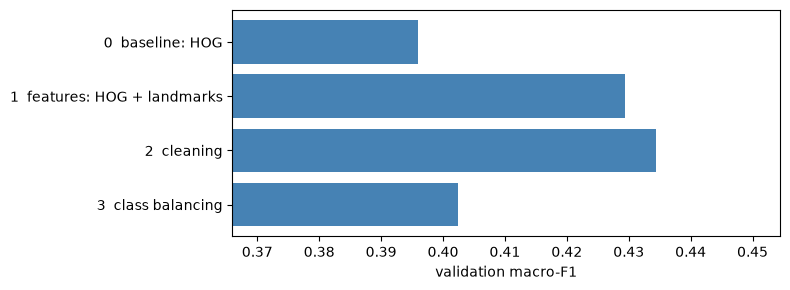

In [35]:
table = pd.DataFrame(results)
table.to_csv("figures/creative_ablation.csv", index=False)
print(table.round(3).to_string(index=False))

plt.figure(figsize=(8, 3))
plt.barh(table["experiment"], table["macro_f1"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlim(table["macro_f1"].min() - 0.03, table["macro_f1"].max() + 0.02)
plt.xlabel("validation macro-F1")
plt.tight_layout()
plt.savefig("figures/creative_ablation.png", dpi=150)
plt.show()

### What to write in the report (for every step)
1. **Why** you tried it (evidence from Task 1: for example the Disgust F1, or the duplicates you found).
2. **What** you did, in enough detail to repeat it.
3. **Result:** the numbers from the table above.
4. **Why you think it helped or not.** Differences below about 0.01 may be noise (the validation set has ~3,600 images). Say so.

### Ideas for extra steps
Stronger augmentation (small shifts, rotations, brightness changes), feature selection, checking mislabelled training images,
or geometric features from KDEF (mouth opening, eyebrow height). For the geometric features, `fer_features.py` already has `extract_geometry`.